### Trabalho da disciplina de Redes Neurais Artificiais
### Alunos: Gustavo Silveira Dias e Michael
### Classificação de Raio X ósseo (fraturado × não fraturado) com CNN 



## 1. Preparação do ambiente

In [20]:
from IPython.display import display, HTML
display(HTML("<style>.container { width:100% !important; }</style>"))

In [21]:
import os, sys, glob, json, hashlib, random, subprocess
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from tabulate import tabulate

from sklearn.metrics import (confusion_matrix, classification_report, roc_curve,
                             roc_auc_score, precision_recall_fscore_support)
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.layers import (Input, Dense, Dropout, Conv2D, MaxPooling2D,
                                     BatchNormalization, Activation, GlobalAveragePooling2D)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2
from tensorflow.keras.initializers import HeNormal
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

print(f"Python:     {sys.version.split()[0]}")
print(f"NumPy:      {np.__version__}")
print(f"OpenCV:     {cv2.__version__}")
print(f"TensorFlow: {tf.__version__}")
gpus = tf.config.list_physical_devices('GPU')
print(f"GPUs:       {gpus if gpus else 'nenhuma (treino será em CPU)'}")

Python:     3.14.8
NumPy:      2.5.4
OpenCV:     5.0.0
TensorFlow: 2.22.0-rc0
GPUs:       nenhuma (treino será em CPU)


In [22]:
# Exporta os pacotes instalados (reprodutibilidade)
def export_requirements():
    try:
        r = subprocess.run([sys.executable, '-m', 'pip', 'freeze'],
                           capture_output=True, text=True, check=True)
        with open('requirements.txt', 'w') as f:
            f.write(r.stdout)
        print("requirements.txt exportado com sucesso!")
    except subprocess.CalledProcessError as e:
        print("Erro ao exportar requirements.txt:", e)

export_requirements()

requirements.txt exportado com sucesso!


## 2. Configurações do experimento



In [23]:
# ===== Caminhos =====
BASE_DIR  = '.'                                  # pasta onde está o notebook
TRAIN_DIR = os.path.join(BASE_DIR, 'Treinamento')
VAL_DIR   = os.path.join(BASE_DIR, 'Validação')
TEST_DIR  = None   # opcional: os.path.join(BASE_DIR, 'Teste') (mesma estrutura de subpastas)

# Índice 0 = negativa, índice 1 = positiva (fratura)
CLASS_NAMES = ['nao-fraturadas', 'fraturadas']
NUM_CLASSES = len(CLASS_NAMES)

# ===== Experimento =====
NEW_MODEL         = False
USE_FILTERS       = True    # filtros de pré-processamento (seção 4)
USE_AUGMENTATION  = True    # data augmentation no treino
USE_CLASS_WEIGHTS = True    # compensa desbalanceamento de classes

IMG_SIZE      = 224         # se o treino estiver lento, tente 160 ou 128
BATCH_SIZE    = 16
EPOCHS        = 100
LEARNING_RATE = 1e-3

# Dica: rode uma vez com USE_FILTERS=True e outra com False e compare as métricas.
MODEL_NAME = 'cnn_fraturas_v2' + ('_filtros' if USE_FILTERS else '_semfiltros')

IMG_EXTS = ('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff')

os.makedirs('models', exist_ok=True)

## 3. Análise dos dados

| Conjunto    | Classe         |   Imagens |
|:------------|:---------------|----------:|
| Treinamento | nao-fraturadas |       132 |
| Treinamento | fraturadas     |       242 |
| Validacao   | nao-fraturadas |       341 |
| Validacao   | fraturadas     |       126 |


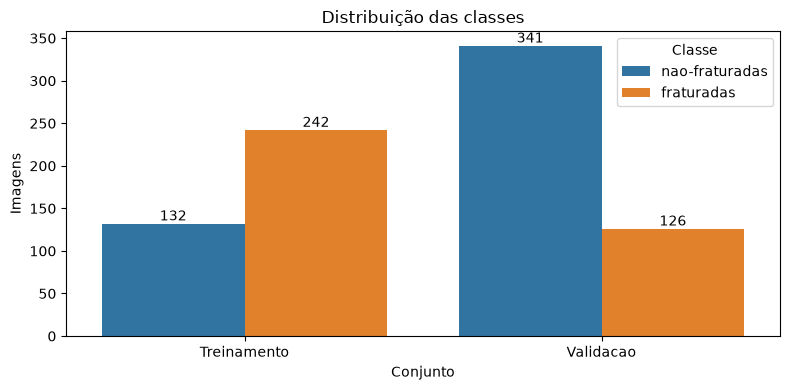


Razão de desbalanceamento no treino: 1.83:1 -> pesos de classe recomendados.


In [24]:
def listar_imagens(pasta):
    return sorted(f for f in glob.glob(os.path.join(pasta, '**', '*'), recursive=True)
                  if f.lower().endswith(IMG_EXTS))

def checar_estrutura(base, nome):
    if not os.path.isdir(base):
        raise FileNotFoundError(
            f"Pasta de {nome} não encontrada: '{os.path.abspath(base)}'.\n"
            f"Pasta atual: '{os.getcwd()}' -> conteúdo: {os.listdir('.')}")
    for c in CLASS_NAMES:
        p = os.path.join(base, c)
        if not os.path.isdir(p):
            raise FileNotFoundError(
                f"Subpasta '{c}' não encontrada em '{base}'. Encontradas: {os.listdir(base)}")

checar_estrutura(TRAIN_DIR, 'Treinamento')
checar_estrutura(VAL_DIR, 'Validacao')
if TEST_DIR: checar_estrutura(TEST_DIR, 'Teste')

linhas = []
for nome, base in [('Treinamento', TRAIN_DIR), ('Validacao', VAL_DIR)] + ([('Teste', TEST_DIR)] if TEST_DIR else []):
    for c in CLASS_NAMES:
        linhas.append([nome, c, len(listar_imagens(os.path.join(base, c)))])
df_cont = pd.DataFrame(linhas, columns=['Conjunto', 'Classe', 'Imagens'])
print(tabulate(df_cont, headers='keys', tablefmt='pipe', showindex=False))

plt.figure(figsize=(8, 4))
ax = sns.barplot(data=df_cont, x='Conjunto', y='Imagens', hue='Classe')
for cont in ax.containers:
    ax.bar_label(cont)
plt.title('Distribuição das classes'); plt.tight_layout(); plt.show()

n = df_cont[df_cont.Conjunto == 'Treinamento'].set_index('Classe')['Imagens']
razao = n.max() / max(n.min(), 1)
print(f"\nRazão de desbalanceamento no treino: {razao:.2f}:1",
      "-> pesos de classe recomendados." if razao > 1.2 else "-> classes razoavelmente balanceadas.")

In [25]:
# Checagem de vazamento: a mesma imagem (conteúdo idêntico) em Treinamento e Validação?
def hash_arquivo(p):
    with open(p, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

h_train = {hash_arquivo(p): p for p in listar_imagens(TRAIN_DIR)}
h_val   = {hash_arquivo(p): p for p in listar_imagens(VAL_DIR)}
duplicadas = set(h_train) & set(h_val)

if duplicadas:
    print(f"ATENÇÃO: {len(duplicadas)} imagens idênticas em Treinamento e Validação!")
    print("Isso infla a acurácia. Exemplos:")
    for h in list(duplicadas)[:5]:
        print("  ", h_train[h], "<->", h_val[h])
else:
    print("OK: nenhuma imagem duplicada entre Treinamento e Validação.")

ATENÇÃO: 47 imagens idênticas em Treinamento e Validação!
Isso infla a acurácia. Exemplos:
   .\Treinamento\fraturadas\9.jpg <-> .\Validação\fraturadas\9.jpg
   .\Treinamento\nao-fraturadas\FA35.jpg <-> .\Validação\nao-fraturadas\IMG0000035.jpg
   .\Treinamento\nao-fraturadas\IMG0004097.jpg <-> .\Validação\nao-fraturadas\IMG0004097.jpg
   .\Treinamento\nao-fraturadas\FA253.jpg <-> .\Validação\nao-fraturadas\IMG0000253.jpg
   .\Treinamento\nao-fraturadas\IMG0004236.jpg <-> .\Validação\nao-fraturadas\IMG0004236.jpg


In [26]:
# Resoluções originais e estatísticas de intensidade (amostra)
amostra = listar_imagens(TRAIN_DIR)
random.Random(SEED).shuffle(amostra)
amostra = amostra[:200]

tamanhos, medias, desvios = [], [], []
for p in amostra:
    im = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
    if im is not None:
        tamanhos.append(im.shape[::-1]); medias.append(im.mean()); desvios.append(im.std())

print(f"Amostra de {len(tamanhos)} imagens do treino")
print(f"Resoluções (largura x altura): mín {min(tamanhos)}, máx {max(tamanhos)}")
print(f"Intensidade média: {np.mean(medias):.1f} (variação entre imagens: ±{np.std(medias):.1f})")
print(f"Contraste médio (desvio-padrão): {np.mean(desvios):.1f}")

Amostra de 200 imagens do treino
Resoluções (largura x altura): mín (373, 454), máx (3364, 2130)
Intensidade média: 57.2 (variação entre imagens: ±18.5)
Contraste médio (desvio-padrão): 46.1


## 4. Filtros de pré-processamento

Pipeline aplicado **nesta ordem** (cada etapa pode ser ligada/desligada em `FILTROS`):

1. **Filtro de mediana** — remove ruído "sal e pimenta" sem borrar bordas (importante: a linha da fratura é uma borda fina).
2. **Esticamento de contraste por percentis** (1%–99%) — descarta pixels extremos (marcadores, bordas pretas) e usa toda a faixa dinâmica.
3. **CLAHE** (equalização adaptativa local de histograma) — realça a textura do osso e a linha de fratura em regiões escuras ou lavadas, sem estourar o ruído como a equalização global.
4. **Unsharp mask** — acentua bordas finas.

Opções extras: `denoise='bilateral'` (preserva bordas, mais suave) ou `'nlm'` (Non-Local Means, melhor qualidade, **bem mais lento**), e `gamma` para clarear/escurecer.

In [27]:
FILTROS = dict(
    denoise='median',        # None | 'median' | 'bilateral' | 'nlm'
    median_ksize=3,
    percentil_baixo=1, percentil_alto=99,   # None para desligar o esticamento
    clahe=True, clahe_clip=2.0, clahe_grid=(8, 8),
    unsharp=True, unsharp_sigma=1.5, unsharp_amount=0.8,
    gamma=None,              # ex.: 0.8 (clareia) ou 1.2 (escurece)
)

def etapas_filtros(img, cfg=FILTROS):
    """Recebe imagem uint8 em tons de cinza. Devolve lista [(nome, imagem), ...] cumulativa."""
    etapas = [('Original', img)]
    x = img

    if cfg['denoise'] == 'median':
        x = cv2.medianBlur(x, cfg['median_ksize']); etapas.append(('Mediana', x))
    elif cfg['denoise'] == 'bilateral':
        x = cv2.bilateralFilter(x, 7, 50, 50);      etapas.append(('Bilateral', x))
    elif cfg['denoise'] == 'nlm':
        x = cv2.fastNlMeansDenoising(x, None, h=7, templateWindowSize=7, searchWindowSize=21)
        etapas.append(('Non-Local Means', x))

    if cfg['percentil_baixo'] is not None:
        lo, hi = np.percentile(x, [cfg['percentil_baixo'], cfg['percentil_alto']])
        if hi > lo:
            x = np.clip((x.astype(np.float32) - lo) / (hi - lo) * 255, 0, 255).astype(np.uint8)
            etapas.append(('Contraste (percentis)', x))

    if cfg['clahe']:
        clahe = cv2.createCLAHE(clipLimit=cfg['clahe_clip'], tileGridSize=cfg['clahe_grid'])
        x = clahe.apply(x); etapas.append(('CLAHE', x))

    if cfg['unsharp']:
        blur = cv2.GaussianBlur(x, (0, 0), cfg['unsharp_sigma'])
        a = cfg['unsharp_amount']
        x = cv2.addWeighted(x, 1 + a, blur, -a, 0); etapas.append(('Unsharp mask', x))

    if cfg['gamma']:
        tab = ((np.arange(256) / 255.0) ** cfg['gamma'] * 255).astype(np.uint8)
        x = cv2.LUT(x, tab); etapas.append((f"Gamma {cfg['gamma']}", x))

    return etapas

def aplicar_filtros(img, cfg=FILTROS):
    return etapas_filtros(img, cfg)[-1][1]

def preprocess_fn(x):
    """Hook do ImageDataGenerator: x = (H, W, 1) float32 em [0, 255]."""
    img = np.clip(x[..., 0], 0, 255).astype(np.uint8)
    return aplicar_filtros(img).astype(np.float32)[..., np.newaxis]

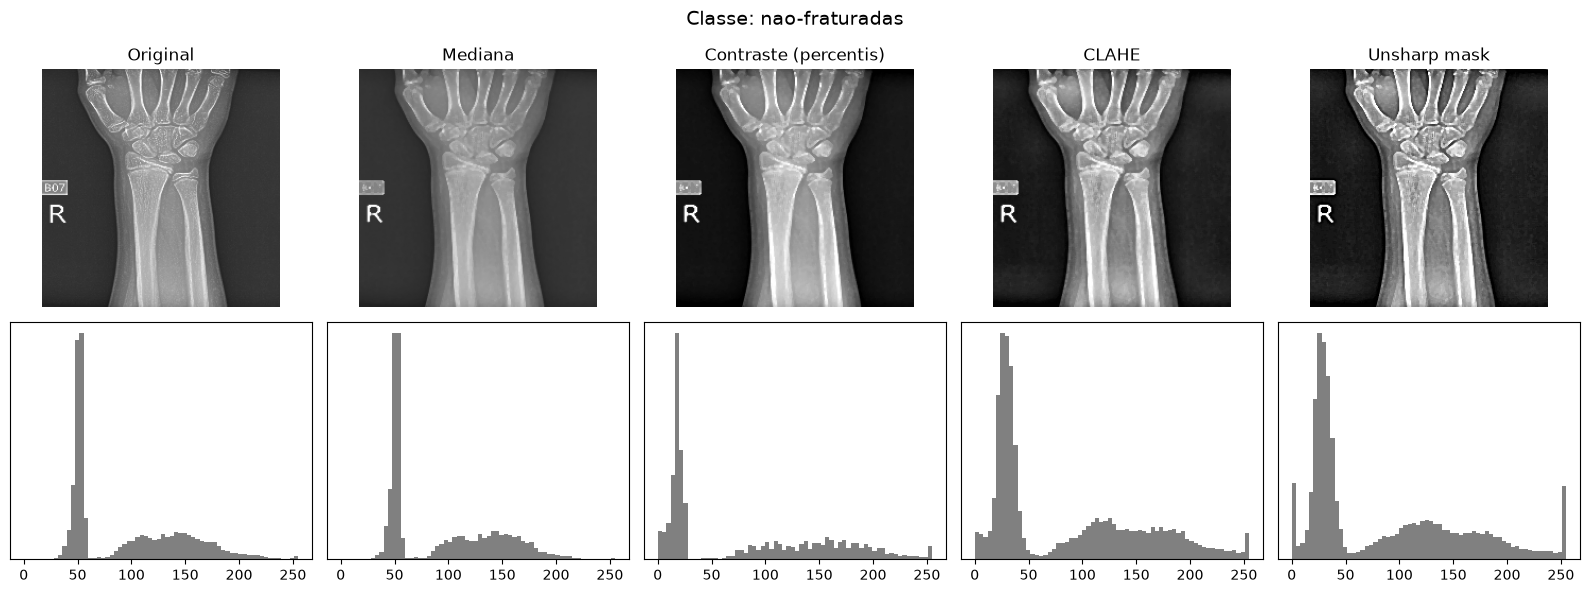

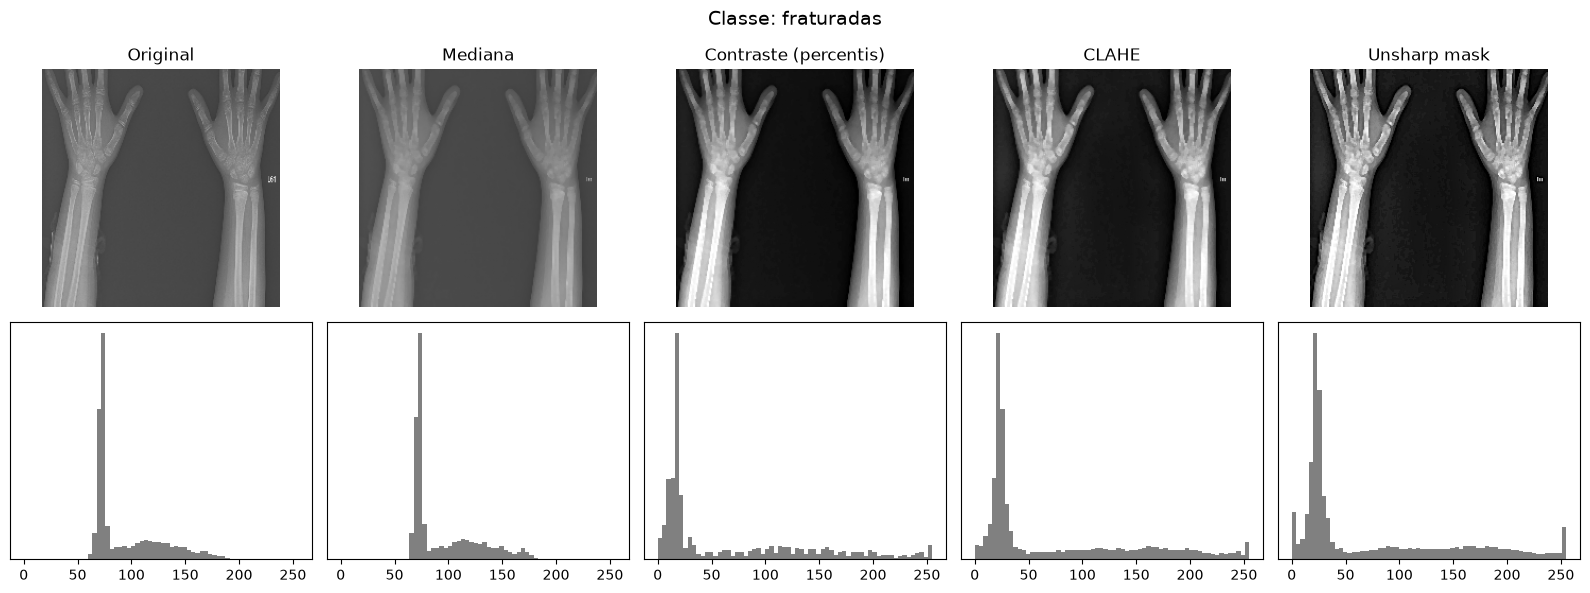

In [28]:
# Visualização das etapas em uma imagem de cada classe
for c in CLASS_NAMES:
    arquivos = listar_imagens(os.path.join(TRAIN_DIR, c))
    img = cv2.imread(arquivos[0], cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)
    etapas = etapas_filtros(img)

    fig, axs = plt.subplots(2, len(etapas), figsize=(3.2 * len(etapas), 6))
    for i, (nome, im) in enumerate(etapas):
        axs[0, i].imshow(im, cmap='gray', vmin=0, vmax=255)
        axs[0, i].set_title(nome); axs[0, i].axis('off')
        axs[1, i].hist(im.ravel(), bins=64, range=(0, 255), color='gray')
        axs[1, i].set_yticks([])
    fig.suptitle(f'Classe: {c}', fontsize=14)
    plt.tight_layout(); plt.show()

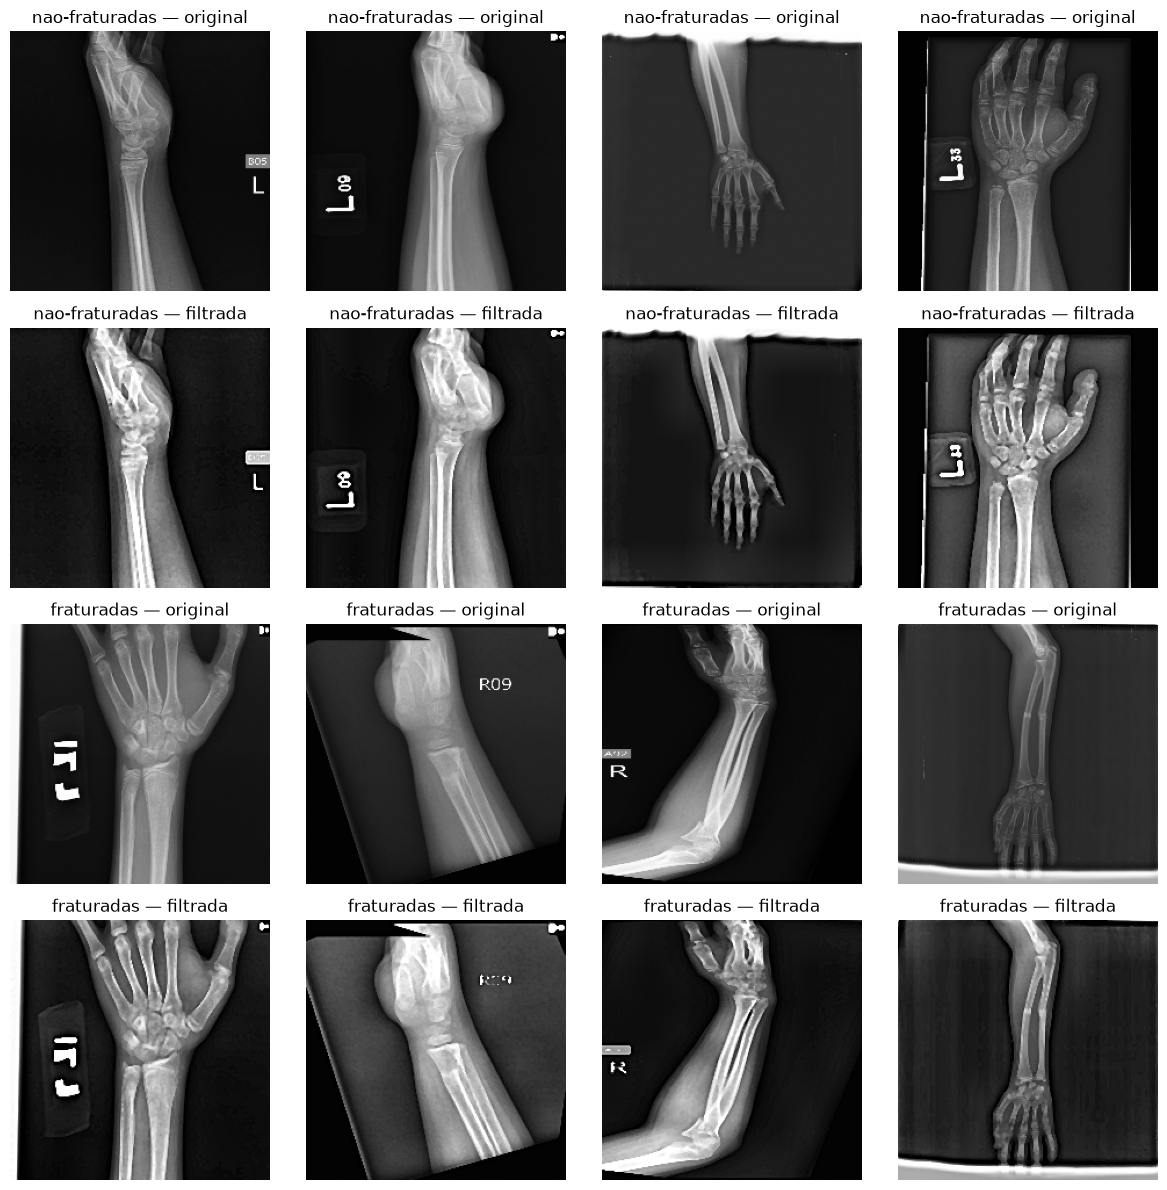

In [29]:
# Comparação direta: sem filtro x com filtro (4 imagens de cada classe)
fig, axs = plt.subplots(NUM_CLASSES * 2, 4, figsize=(12, 6 * NUM_CLASSES))
for ci, c in enumerate(CLASS_NAMES):
    arqs = listar_imagens(os.path.join(TRAIN_DIR, c))
    rng = random.Random(SEED + ci); rng.shuffle(arqs)
    for j, p in enumerate(arqs[:4]):
        im = cv2.resize(cv2.imread(p, cv2.IMREAD_GRAYSCALE), (IMG_SIZE, IMG_SIZE))
        axs[ci * 2,     j].imshow(im, cmap='gray');                  axs[ci * 2,     j].set_title(f'{c} — original'); axs[ci * 2,     j].axis('off')
        axs[ci * 2 + 1, j].imshow(aplicar_filtros(im), cmap='gray'); axs[ci * 2 + 1, j].set_title(f'{c} — filtrada');  axs[ci * 2 + 1, j].axis('off')
plt.tight_layout(); plt.show()

## 5. Geradores de dados (filtros + data augmentation)

- **Treino:** augmentation geométrico leve (rotação, deslocamento, zoom, espelhamento horizontal) com fundo **preto** (`fill_mode='constant'`), que combina com raio X. Depois, os filtros e o `rescale`.
- **Validação/Teste:** **sem** augmentation, apenas filtros + `rescale` (as mesmas transformações determinísticas do treino).
- Não usamos espelhamento vertical nem rotações grandes: ossos têm orientação anatômica típica.

In [30]:
AUG = dict(
    rotation_range=15,
    width_shift_range=0.10,
    height_shift_range=0.10,
    zoom_range=0.10,
    shear_range=0.05,
    horizontal_flip=True,
    fill_mode='constant', cval=0,
)

pre = preprocess_fn if USE_FILTERS else None

train_datagen = ImageDataGenerator(preprocessing_function=pre, rescale=1./255,
                                   **(AUG if USE_AUGMENTATION else {}))
eval_datagen  = ImageDataGenerator(preprocessing_function=pre, rescale=1./255)

common = dict(target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE, class_mode='binary',
              classes=CLASS_NAMES, color_mode='grayscale', interpolation='bilinear')

from PIL import Image

def dataframe_imagens_validas(diretorio):
    """Lista imagens decodificáveis sem modificar ou apagar arquivos do dataset."""
    registros = []
    invalidas = []

    for classe in CLASS_NAMES:
        pasta_classe = os.path.join(diretorio, classe)
        if not os.path.isdir(pasta_classe):
            raise FileNotFoundError(f"Pasta da classe não encontrada: {pasta_classe}")

        for raiz, _, nomes in os.walk(pasta_classe):
            for nome in nomes:
                if os.path.splitext(nome)[1].lower() not in IMG_EXTS:
                    continue

                caminho = os.path.abspath(os.path.join(raiz, nome))
                try:
                    with Image.open(caminho) as imagem:
                        imagem.load()
                except (OSError, ValueError) as erro:
                    invalidas.append((caminho, str(erro)))
                    continue

                registros.append({'filename': caminho, 'class': classe})

    if invalidas:
        print(f"\n{len(invalidas)} imagem(ns) inválida(s) ignorada(s) em {diretorio}:")
        for caminho, erro in invalidas:
            print(f" - {caminho}: {erro}")

    dataframe = pd.DataFrame(registros)
    classes_ausentes = set(CLASS_NAMES) - set(dataframe['class'].unique()) if not dataframe.empty else set(CLASS_NAMES)
    if classes_ausentes:
        raise ValueError(f"Sem imagens válidas para as classes: {sorted(classes_ausentes)} em {diretorio}")

    return dataframe

def criar_gerador(diretorio, datagen, shuffle):
    dataframe = dataframe_imagens_validas(diretorio)
    return datagen.flow_from_dataframe(
        dataframe=dataframe,
        directory=None,
        x_col='filename',
        y_col='class',
        shuffle=shuffle,
        seed=SEED if shuffle else None,
        **common,
    )

train_generator = criar_gerador(TRAIN_DIR, train_datagen, shuffle=True)
val_generator   = criar_gerador(VAL_DIR, eval_datagen, shuffle=False)

if TEST_DIR:
    test_generator = criar_gerador(TEST_DIR, eval_datagen, shuffle=False)
else:
    test_generator = val_generator
    print("\nAVISO: sem pasta de teste — as métricas finais usarão a validação, que também decide o")
    print("early stopping. Os números tendem a ser um pouco otimistas. Ideal: separar um conjunto de teste.")

print(f"\nÍndices das classes: {train_generator.class_indices}")
assert train_generator.class_indices == {c: i for i, c in enumerate(CLASS_NAMES)}

Found 374 validated image filenames belonging to 2 classes.

12 imagem(ns) inválida(s) ignorada(s) em .\Validação:
 - c:\Users\gusta\OneDrive\Área de Trabalho\Computação\Engenharia de Computação\Computação-2026.2\PDI\predict_fractures\Validação\nao-fraturadas\IMG0004073.jpg: image file is truncated (3 bytes not processed)
 - c:\Users\gusta\OneDrive\Área de Trabalho\Computação\Engenharia de Computação\Computação-2026.2\PDI\predict_fractures\Validação\nao-fraturadas\IMG0004119.jpg: image file is truncated (6 bytes not processed)
 - c:\Users\gusta\OneDrive\Área de Trabalho\Computação\Engenharia de Computação\Computação-2026.2\PDI\predict_fractures\Validação\nao-fraturadas\IMG0004129.jpg: image file is truncated (6 bytes not processed)
 - c:\Users\gusta\OneDrive\Área de Trabalho\Computação\Engenharia de Computação\Computação-2026.2\PDI\predict_fractures\Validação\nao-fraturadas\IMG0004130.jpg: image file is truncated (8 bytes not processed)
 - c:\Users\gusta\OneDrive\Área de Trabalho\Compu

In [31]:
# Pesos de classe
if USE_CLASS_WEIGHTS:
    pesos = compute_class_weight('balanced', classes=np.arange(NUM_CLASSES), y=train_generator.classes)
    class_weight = {i: float(w) for i, w in enumerate(pesos)}
else:
    class_weight = None
print("Pesos de classe:", {CLASS_NAMES[k]: round(v, 3) for k, v in (class_weight or {}).items()} or "desligado")

Pesos de classe: {'nao-fraturadas': 1.417, 'fraturadas': 0.773}


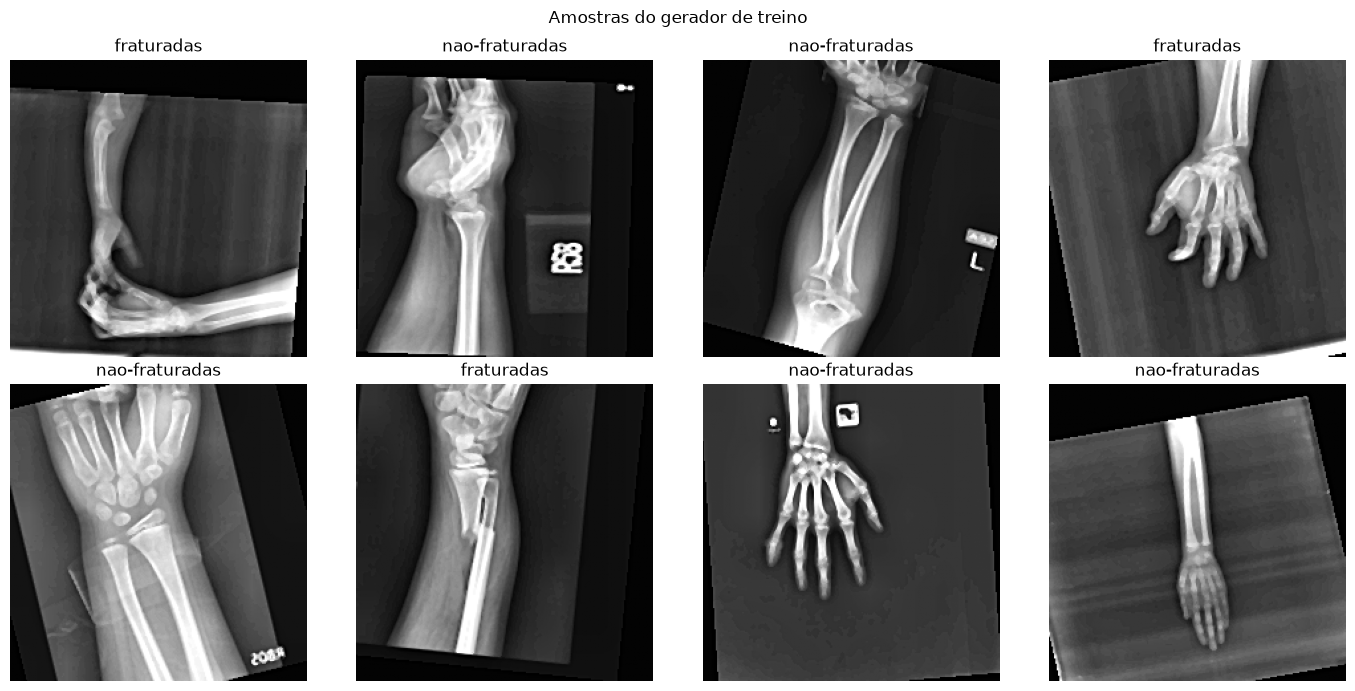

In [32]:
# O que a rede realmente "enxerga" no treino (augmentation + filtros)
imgs, labs = next(train_generator)
n_show = min(8, len(imgs))
fig, axs = plt.subplots(2, 4, figsize=(14, 7))
for i, ax in enumerate(axs.ravel()[:n_show]):
    ax.imshow(imgs[i].squeeze(), cmap='gray', vmin=0, vmax=1)
    ax.set_title(CLASS_NAMES[int(labs[i])]); ax.axis('off')
plt.suptitle('Amostras do gerador de treino'); plt.tight_layout(); plt.show()

## 6. Construção do modelo

CNN com 4 blocos convolucionais (32 → 64 → 128 → 256 filtros), `Conv → BatchNorm → ReLU`, regularização L2 leve, *Dropout* e **GlobalAveragePooling** no lugar de `Flatten` (reduz muito o número de parâmetros e o overfitting). Saída `sigmoid` = probabilidade de **fratura**.

In [33]:
def bloco_conv(x, filtros, n_convs=2, drop=0.25):
    for _ in range(n_convs):
        x = Conv2D(filtros, (3, 3), padding='same', use_bias=False,
                   kernel_initializer=HeNormal(), kernel_regularizer=l2(1e-4))(x)
        x = BatchNormalization()(x)
        x = Activation('relu')(x)
    x = MaxPooling2D((2, 2))(x)
    return Dropout(drop)(x)

def construir_modelo(img_size, nome):
    entrada = Input(shape=(img_size, img_size, 1), name='input')
    x = bloco_conv(entrada, 32, 2, 0.10)
    x = bloco_conv(x,       64, 2, 0.15)
    x = bloco_conv(x,      128, 2, 0.20)
    x = bloco_conv(x,      256, 2, 0.25)
    x = GlobalAveragePooling2D()(x)
    x = Dense(128, kernel_initializer=HeNormal(), kernel_regularizer=l2(1e-4))(x)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)
    x = Dropout(0.5)(x)
    saida = Dense(1, activation='sigmoid', name='output')(x)
    return Model(entrada, saida, name=nome)

cnn_model = construir_modelo(IMG_SIZE, MODEL_NAME)
cnn_model.summary()

Model: "cnn_fraturas_v2_filtros"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 224, 224, 32)   │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_9 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 224, 224, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_10 (Activation)      │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_11 (Activation)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 112, 112, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_12 (Activation)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_13 (Activation)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 56, 56, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 1,208,097 (4.61 MB)

 Trainable params: 1,205,921 (4.60 MB)

 Non-trainable params: 2,176 (8.50 KB)

In [34]:
from pathlib import Path
from PIL import Image

raiz = Path("Treinamento")
extensoes = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
com_problema = []

for caminho in raiz.rglob("*"):
    if caminho.is_file() and caminho.suffix.lower() in extensoes:
        try:
            with Image.open(caminho) as imagem:
                imagem.load()  # força a decodificação completa
        except (OSError, ValueError) as erro:
            com_problema.append((caminho, erro))

for caminho, erro in com_problema:
    print(f"{caminho}: {erro}")

print(f"Total de imagens problemáticas: {len(com_problema)}")

Total de imagens problemáticas: 0


## 7. Treinamento

- **Métricas:** acurácia, precisão, *recall* (sensibilidade) e AUC.
- **ReduceLROnPlateau:** reduz a taxa de aprendizado pela metade quando a `val_loss` estagna.
- **EarlyStopping:** para quando a `val_loss` não melhora e restaura os melhores pesos.
- **ModelCheckpoint:** salva o melhor modelo em `models/`.

In [35]:
MODEL_PATH   = os.path.join('models', MODEL_NAME + '.keras')
HISTORY_PATH = os.path.join('models', MODEL_NAME + '_history.json')

if NEW_MODEL:
    cnn_model.compile(
        optimizer=Adam(learning_rate=LEARNING_RATE),
        loss='binary_crossentropy',
        metrics=['accuracy',
                 tf.keras.metrics.Precision(name='precision'),
                 tf.keras.metrics.Recall(name='recall'),
                 tf.keras.metrics.AUC(name='auc')])

    callbacks = [
        ModelCheckpoint(MODEL_PATH, monitor='val_loss', mode='min', save_best_only=True),
        EarlyStopping(monitor='val_loss', mode='min', patience=15, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', mode='min', factor=0.5, patience=5, min_lr=1e-6, verbose=1),
    ]

    history = cnn_model.fit(
        train_generator,
        validation_data=val_generator,
        epochs=EPOCHS,
        callbacks=callbacks,
        class_weight=class_weight,
        verbose=1)

    with open(HISTORY_PATH, 'w') as f:
        json.dump({k: [float(v) for v in vals] for k, vals in history.history.items()}, f)
    cnn_model = load_model(MODEL_PATH)   # melhor modelo salvo

    # Guarda a configuração para a inferência usar exatamente o mesmo pré-processamento
    with open(os.path.join('models', MODEL_NAME + '_config.json'), 'w') as f:
        json.dump(dict(class_names=CLASS_NAMES, img_size=IMG_SIZE, use_filters=USE_FILTERS,
                       filtros={k: (list(v) if isinstance(v, tuple) else v) for k, v in FILTROS.items()}),
                  f, indent=2, ensure_ascii=False)
else:
    cnn_model = load_model(MODEL_PATH)
    print("Modelo carregado de", MODEL_PATH)

Modelo carregado de models\cnn_fraturas_v2_filtros.keras


In [36]:
# Aviso sonoro opcional (não quebra se o pygame/arquivo não existir)
try:
    import pygame
    mp3 = 'support_files/mario_coin.mp3'
    if os.path.exists(mp3):
        pygame.mixer.init(); pygame.mixer.music.load(mp3); pygame.mixer.music.play()
        while pygame.mixer.music.get_busy():
            pygame.time.wait(100)
except Exception as e:
    pass
print('Sucesso!')

Sucesso!


## 8. Curvas de aprendizado

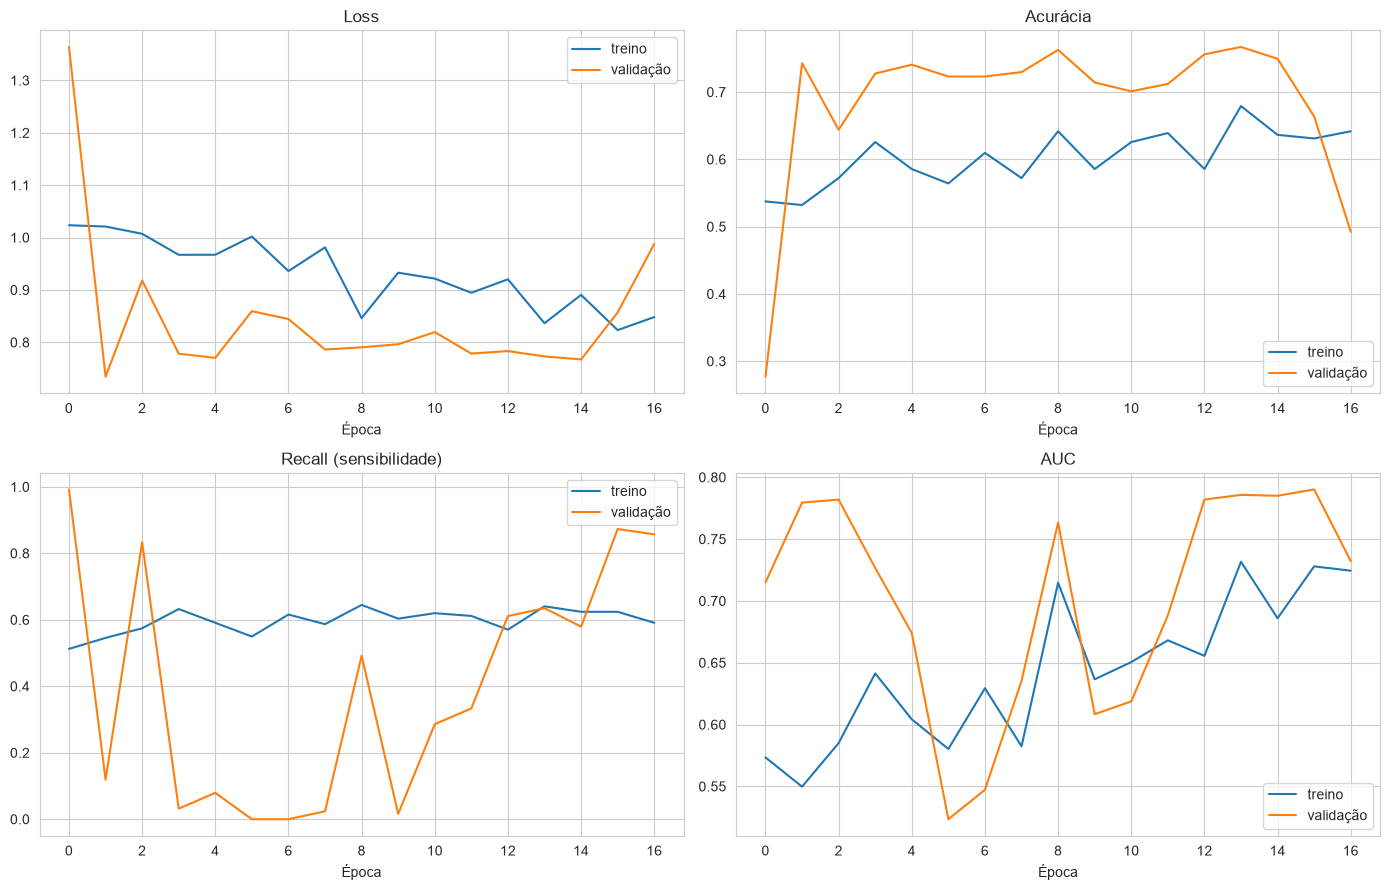

In [37]:
with open(HISTORY_PATH) as f:
    history = json.load(f)

sns.set_style('whitegrid')
fig, axs = plt.subplots(2, 2, figsize=(14, 9))
for ax, (chave, titulo) in zip(axs.ravel(), [('loss', 'Loss'), ('accuracy', 'Acurácia'),
                                              ('recall', 'Recall (sensibilidade)'), ('auc', 'AUC')]):
    if chave in history:
        ax.plot(history[chave], label='treino')
        ax.plot(history['val_' + chave], label='validação')
    ax.set_title(titulo); ax.set_xlabel('Época'); ax.legend()
plt.tight_layout(); plt.show()

## 9. Avaliação

Em diagnóstico por imagem, o erro mais grave é o **falso negativo** (fratura não detectada). Por isso olhamos o *recall* da classe "Fraturadas" e não só a acurácia. Também calculamos o **limiar ótimo** (índice de Youden: maximiza sensibilidade + especificidade) em vez de usar sempre 0,5.

In [38]:
test_generator.reset()
y_prob = cnn_model.predict(test_generator, verbose=0).ravel()
y_true = test_generator.classes
print(f"Predições: {len(y_prob)} | Rótulos: {len(y_true)}")

# Limiar ótimo (Youden)
fpr, tpr, thr = roc_curve(y_true, y_prob)
limiar_otimo = float(thr[np.argmax(tpr - fpr)])
auc = roc_auc_score(y_true, y_prob)
print(f"AUC-ROC: {auc:.4f} | Limiar ótimo (Youden): {limiar_otimo:.3f}")

def relatorio(limiar, titulo):
    y_pred = (y_prob >= limiar).astype(int)
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    print(f"\n===== {titulo} (limiar = {limiar:.3f}) =====")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))
    print(f"Sensibilidade (recall de fratura): {tp / max(tp + fn, 1):.4f}")
    print(f"Especificidade:                    {tn / max(tn + fp, 1):.4f}")
    print(f"Fraturas não detectadas (FN): {fn} | Falsos alarmes (FP): {fp}")
    return cm

cm_05  = relatorio(0.5, 'Limiar padrão')
cm_opt = relatorio(limiar_otimo, 'Limiar ótimo')

Predições: 455 | Rótulos: 455
AUC-ROC: 0.7798 | Limiar ótimo (Youden): 0.261

===== Limiar padrão (limiar = 0.500) =====
                precision    recall  f1-score   support

nao-fraturadas     0.7442    0.9818    0.8467       329
    fraturadas     0.7143    0.1190    0.2041       126

      accuracy                         0.7429       455
     macro avg     0.7293    0.5504    0.5254       455
  weighted avg     0.7359    0.7429    0.6687       455

Sensibilidade (recall de fratura): 0.1190
Especificidade:                    0.9818
Fraturas não detectadas (FN): 111 | Falsos alarmes (FP): 6

===== Limiar ótimo (limiar = 0.261) =====
                precision    recall  f1-score   support

nao-fraturadas     0.8954    0.6505    0.7535       329
    fraturadas     0.4676    0.8016    0.5906       126

      accuracy                         0.6923       455
     macro avg     0.6815    0.7260    0.6721       455
  weighted avg     0.7769    0.6923    0.7084       455

Sensibilidade (

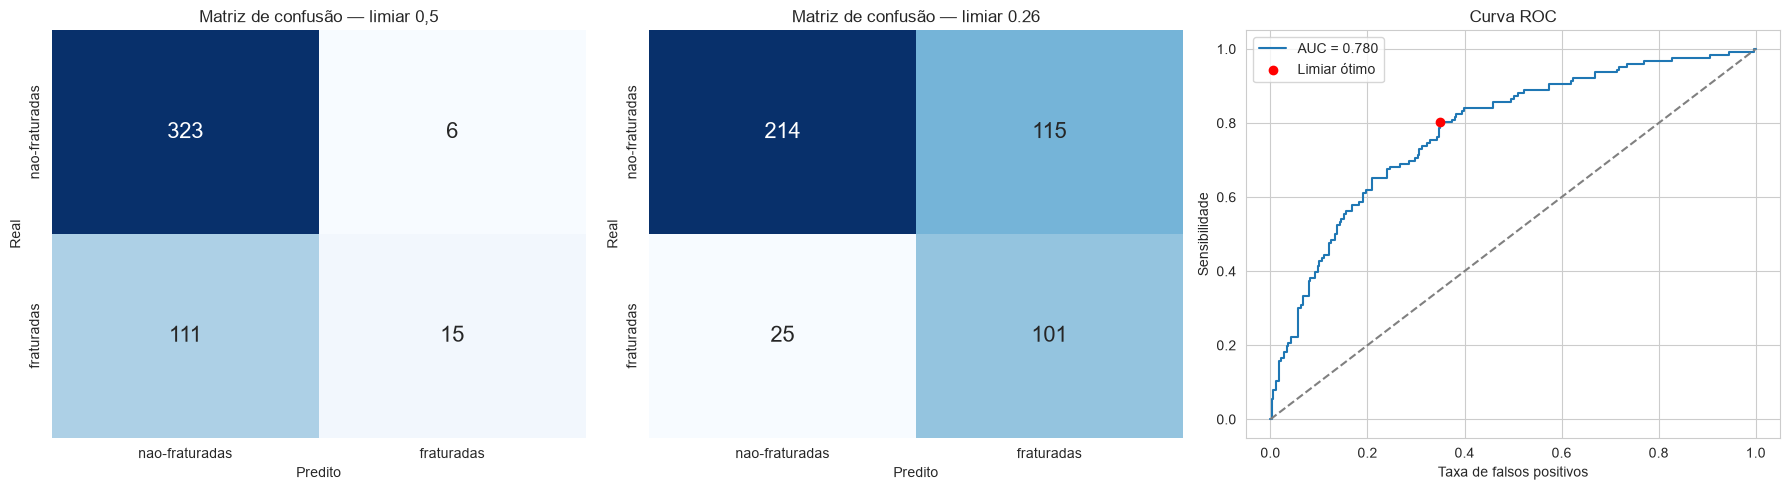

In [39]:
fig, axs = plt.subplots(1, 3, figsize=(18, 5))

for ax, cm, tit in [(axs[0], cm_05, 'Matriz de confusão — limiar 0,5'),
                    (axs[1], cm_opt, f'Matriz de confusão — limiar {limiar_otimo:.2f}')]:
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, annot_kws={'size': 16})
    ax.set_xlabel('Predito'); ax.set_ylabel('Real'); ax.set_title(tit)

axs[2].plot(fpr, tpr, label=f'AUC = {auc:.3f}')
axs[2].plot([0, 1], [0, 1], '--', color='gray')
i = np.argmax(tpr - fpr)
axs[2].scatter(fpr[i], tpr[i], color='red', zorder=5, label='Limiar ótimo')
axs[2].set_xlabel('Taxa de falsos positivos'); axs[2].set_ylabel('Sensibilidade')
axs[2].set_title('Curva ROC'); axs[2].legend()
plt.tight_layout(); plt.show()

## 10. Análise dos erros

140 imagens classificadas incorretamente de 455


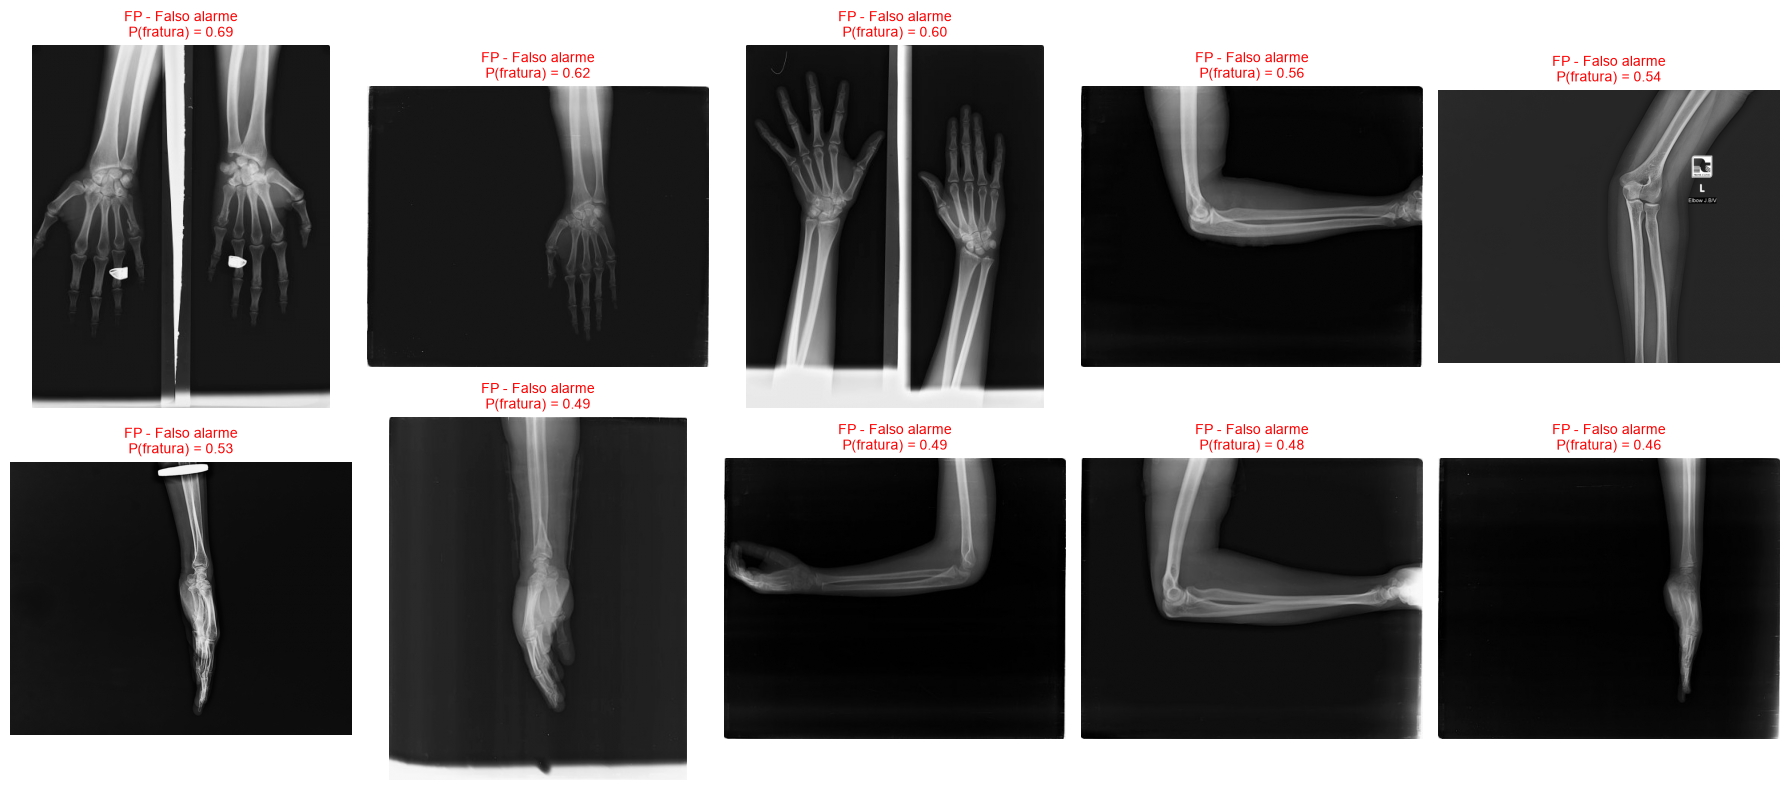

In [47]:

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Classificação usando o limiar ótimo
y_pred_opt = (y_prob >= limiar_otimo).astype(int)

# Identificar erros
erros = np.where(y_pred_opt != y_true)[0]

# Ordenar pelos erros mais confiantes
erros = erros[
    np.argsort(-np.abs(y_prob[erros] - limiar_otimo))
]

print(f"{len(erros)} imagens classificadas incorretamente de {len(y_true)}")

if len(erros) > 0:

    n_show = min(10, len(erros))
    cols = 5
    rows = int(np.ceil(n_show / cols))

    fig, axs = plt.subplots(
        rows, cols,
        figsize=(18, 4 * rows)
    )

    axs = np.atleast_1d(axs).ravel()

    for ax in axs:
        ax.axis("off")

    for ax, idx in zip(axs, erros[:n_show]):

        # Caminho da radiografia
        caminho = test_generator.filepaths[idx]

        # Carregar com PIL
        with Image.open(caminho) as imagem:
            im = imagem.convert("L").copy()

        # Exibir radiografia
        ax.imshow(im, cmap="gray")

        # Identificar tipo de erro
        if y_true[idx] == 1 and y_pred_opt[idx] == 0:
            tipo = "FN - Fratura perdida"
        else:
            tipo = "FP - Falso alarme"

        ax.set_title(
            f"{tipo}\nP(fratura) = {y_prob[idx]:.2f}",
            color="red",
            fontsize=10
        )

    # Remover espaços não utilizados
    for ax in axs[n_show:]:
        fig.delaxes(ax)

    plt.tight_layout()
    plt.show()

else:
    print("Nenhum erro de classificação encontrado.")


## 11. Predição em uma imagem nova

Aplica **exatamente** o mesmo pipeline do treino (redimensionamento bilinear → filtros → normalização).

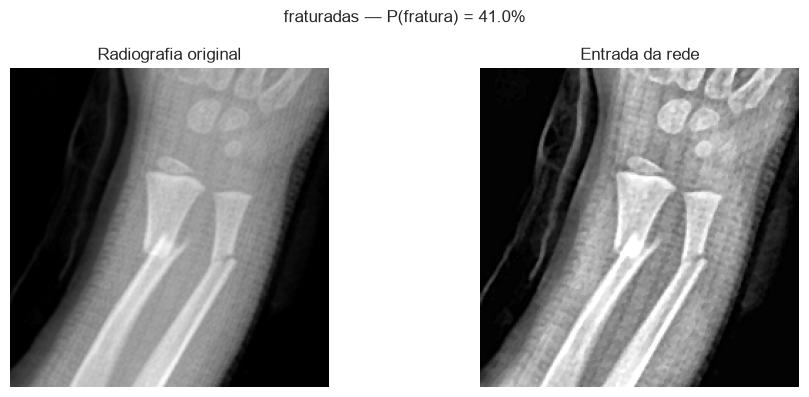

('fraturadas', 0.40995165705680847)


In [ ]:

def prever_imagem(caminho, limiar=None, mostrar=True):

    limiar = limiar_otimo if limiar is None else limiar

    # Verificar se o arquivo existe
    if not os.path.isfile(caminho):
        raise FileNotFoundError(
            f"Arquivo não encontrado: {caminho}"
        )

    # Carregar imagem em escala de cinza usando PIL
    with Image.open(caminho) as arquivo:
        img = np.array(arquivo.convert("L"))

    # Redimensionar conforme o tamanho utilizado no treinamento
    img = np.array(
        Image.fromarray(img).resize(
            (IMG_SIZE, IMG_SIZE),
            Image.Resampling.BILINEAR
        )
    )

    # Aplicar os mesmos filtros utilizados no treinamento
    proc = aplicar_filtros(img) if USE_FILTERS else img

    # Garantir que a saída dos filtros seja uma imagem válida
    proc = np.asarray(proc)

    if proc.shape != (IMG_SIZE, IMG_SIZE):
        raise ValueError(
            f"Formato inesperado após o processamento: {proc.shape}"
        )

    if not np.issubdtype(proc.dtype, np.number):
        raise TypeError("A imagem processada não contém dados numéricos.")

    if not np.isfinite(proc).all():
        raise ValueError("A imagem processada contém valores inválidos.")

    # Normalizar os pixels, como no treinamento
    x = (
        proc.astype(np.float32) / 255.0
    )[np.newaxis, ..., np.newaxis]

    # Prever probabilidade de fratura
    p = float(cnn_model.predict(x, verbose=0)[0, 0])

    if not 0 <= p <= 1:
        raise ValueError(f"Probabilidade inesperada: {p}")

    # Interpretar a classificação
    rotulo = CLASS_NAMES[int(p >= limiar)]

    # Mostrar resultados
    if mostrar:
        fig, axs = plt.subplots(1, 2, figsize=(10, 4))

        axs[0].imshow(img, cmap="gray")
        axs[0].set_title("Radiografia original")
        axs[0].axis("off")

        axs[1].imshow(proc, cmap="gray")
        axs[1].set_title("Entrada da rede")
        axs[1].axis("off")

        plt.suptitle(
            f"{rotulo} — P(fratura) = {p:.1%}"
        )

        plt.tight_layout()
        plt.show()

    return rotulo, p


# Exemplo de utilização
exemplo = r"Seu_caminho_para_uma_imagem_de_teste_aqui.jpg" 

print(prever_imagem(exemplo))
